# RQ3 — Regime Calibration Curves (Optimised FNN, 72 h)

Compares **Global CP** and **Mondrian CP** at nominal coverage **80%, 90%, 95%**, separately in four ocean regimes. Uses **saved FNN predictions**; **no retraining**. Outputs one four-panel calibration figure, one four-panel coverage–area figure, and CSVs. All thresholds are estimated **only on calibration cases**; test cases are used only for evaluation.

**Run from the DATA3001 project folder.** Requires `RQ2/data/forecast_case_regimes.csv`, `data/processed/forecast_origins.parquet`, `data/processed/region_A_observations.parquet`, and `RQ3/optimised_fnn/output/optimised_fnn_calibration_test_predictions.npz`.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data'/'processed'/'forecast_origins.parquet').exists()), None)
if PROJECT is None:
    raise FileNotFoundError('Open the DATA3001 project root (containing data/processed) before running.')
ROOT = PROJECT / 'RQ3' / 'optimised_fnn' / 'output'
ROOT.mkdir(parents=True, exist_ok=True)
REGIME_PATH = PROJECT / 'RQ2' / 'data' / 'forecast_case_regimes.csv'
CACHE_PATH = ROOT / 'optimised_fnn_calibration_test_predictions.npz'
for p in [REGIME_PATH, CACHE_PATH]:
    if not p.exists(): raise FileNotFoundError(f'Missing required input: {p}')
LEVELS = [0.80, 0.90, 0.95]
REGIMES = ['Shelf', 'Kuroshio Core', 'Transition', 'Other Offshore']
R = 6371.0
print('Project:', PROJECT)


Project: /Users/qiuyurui/Desktop/Data3001


In [13]:
# Rebuild observed 72-hour endpoints and compare against cached FNN predictions.
origins = pd.read_parquet(PROJECT/'data'/'processed'/'forecast_origins.parquet').sort_values('forecast_case_id').reset_index(drop=True)
obs = pd.read_parquet(PROJECT/'data'/'processed'/'region_A_observations.parquet', columns=['ID','segment_id','segment_step','latitude','longitude'])
regimes = pd.read_csv(REGIME_PATH).sort_values('forecast_case_id').reset_index(drop=True)
assert origins.forecast_case_id.equals(regimes.forecast_case_id), 'Regime IDs do not match forecast origins'
cal = origins.loc[origins.partition.eq('calibration')].copy()
test = origins.loc[origins.partition.eq('test')].copy()
assert (len(cal),len(test)) == (769,757)
cache = np.load(CACHE_PATH, allow_pickle=False)
assert np.array_equal(cache['cal_case_ids'],cal.forecast_case_id.to_numpy())
assert np.array_equal(cache['test_case_ids'],test.forecast_case_id.to_numpy())

def haversine(lat1,lon1,lat2,lon2):
    a1,o1,a2,o2 = map(np.deg2rad,[lat1,lon1,lat2,lon2])
    a=np.sin((a2-a1)/2)**2 + np.cos(a1)*np.cos(a2)*np.sin((o2-o1)/2)**2
    return 2*R*np.arcsin(np.sqrt(np.clip(a,0,1)))

def destination(lat0,lon0,east,north):
    a0,o0=np.deg2rad(lat0),np.deg2rad(lon0)
    bearing=np.arctan2(east,north)
    angular=np.hypot(east,north)/R
    lat=np.arcsin(np.sin(a0)*np.cos(angular)+np.cos(a0)*np.sin(angular)*np.cos(bearing))
    lon=o0+np.arctan2(np.sin(bearing)*np.sin(angular)*np.cos(a0),np.cos(angular)-np.sin(a0)*np.sin(lat))
    return np.rad2deg(lat),(np.rad2deg(lon)+180)%360-180

def errors_at_72(frame, predictions):
    truth=frame[['forecast_case_id','ID','segment_id','target_start_step','origin_latitude','origin_longitude']].copy()
    truth['segment_step']=truth['target_start_step']+71
    truth=truth.merge(obs,on=['ID','segment_id','segment_step'],how='left',validate='one_to_one',sort=False)
    assert np.array_equal(
    truth["forecast_case_id"].to_numpy(),
    frame["forecast_case_id"].to_numpy()
), "Case ID order mismatch after merge"
    assert truth[['latitude','longitude']].notna().all().all()
    p=predictions.reshape(-1,72,2)[:,-1,:]
    lat,lon=destination(frame.origin_latitude.to_numpy(),frame.origin_longitude.to_numpy(),p[:,0],p[:,1])
    return haversine(lat,lon,truth.latitude.to_numpy(),truth.longitude.to_numpy())

cal_error=errors_at_72(cal,cache['fnn_cal'])
test_error=errors_at_72(test,cache['fnn_test'])
cal_reg=regimes.loc[origins.partition.eq('calibration'),'regime'].to_numpy()
test_reg=regimes.loc[origins.partition.eq('test'),'regime'].to_numpy()
assert set(cal_reg)==set(REGIMES) and set(test_reg)==set(REGIMES)
print('72h errors ready:',len(cal_error),'calibration,',len(test_error),'test')


72h errors ready: 769 calibration, 757 test


In [14]:
# Check the original function again
print("Calibration:")
print("Number of cases:", len(cal))
print("Prediction shape:", cache["fnn_cal"].shape)

print("\nTest:")
print("Number of cases:", len(test))
print("Prediction shape:", cache["fnn_test"].shape)

print("\nRechecking errors:")
cal_error = errors_at_72(cal, cache["fnn_cal"])
test_error = errors_at_72(test, cache["fnn_test"])

print("Calibration errors:", len(cal_error))
print("Test errors:", len(test_error))
print("All checks passed!")

Calibration:
Number of cases: 769
Prediction shape: (769, 144)

Test:
Number of cases: 757


Prediction shape: (757, 144)

Rechecking errors:
Calibration errors: 769
Test errors: 757
All checks passed!


In [15]:
# Split-conformal finite-sample quantile; calculate all thresholds on calibration errors only.
def conformal_q(scores, nominal):
    scores=np.sort(np.asarray(scores,dtype=float))
    rank=int(np.ceil((len(scores)+1)*nominal))
    return float(scores[rank-1]) if rank<=len(scores) else float('inf')

def circle_area(radius):
    return float(2*np.pi*R**2*(1-np.cos(radius/R)))

rows=[]
for regime in REGIMES:
    cm=(cal_reg==regime)
    tm=(test_reg==regime)
    for nominal in LEVELS:
        for method in ['Global','Mondrian']:
            scores=cal_error if method=='Global' else cal_error[cm]
            radius=conformal_q(scores,nominal)
            rows.append(dict(regime=regime,method=method,nominal_coverage=nominal,
                             n_cal=int(cm.sum()),n_test=int(tm.sum()),
                             empirical_coverage=float(np.mean(test_error[tm]<=radius)),
                             radius_km=radius,area_km2=circle_area(radius)))
results=pd.DataFrame(rows)
results.to_csv(ROOT/'optimised_fnn_regime_multi_nominal_72h.csv',index=False)

# Reproduce the existing 90% summary as an integrity check.
reference=pd.read_csv(ROOT/'optimised_fnn_conformal_regime_summary.csv')
reference=reference[reference['model'].eq('Optimised FNN')]
for _, row in results[results.nominal_coverage.eq(.90)].iterrows():
    old=reference[(reference.regime==row.regime)&(reference.method==row.method)]
    assert len(old)==1
    assert abs(float(old.iloc[0]['coverage_72h'])-row.empirical_coverage)<1e-10, f'Coverage mismatch: {row.regime}, {row.method}'
    assert abs(float(old.iloc[0]['radius_72h_km'])-row.radius_km)<1e-8, f'Radius mismatch: {row.regime}, {row.method}'
print('PASS: All eight 90% regime results match validated Optimised FNN outputs.')
display(results.round(4))


PASS: All eight 90% regime results match validated Optimised FNN outputs.


,regime,method,nominal_coverage,n_cal,n_test,empirical_coverage,radius_km,area_km2
0,Shelf,Global,0.80,200,112,0.9375,81.8870,21065.6175
1,Shelf,Mondrian,0.80,200,112,0.8304,49.5783,7722.0305
2,Shelf,Global,0.90,200,112,0.9732,101.8738,32603.6207
3,Shelf,Mondrian,0.90,200,112,0.9018,61.0206,11697.6771
4,Shelf,Global,0.95,200,112,0.9821,126.4184,50206.0472
5,Shelf,Mondrian,0.95,200,112,0.9375,76.3228,18300.0748
6,Kuroshio Core,Global,0.80,120,139,0.6475,81.8870,21065.6175
7,Kuroshio Core,Mondrian,0.80,120,139,0.8561,115.3035,41766.0402
8,Kuroshio Core,Global,0.90,120,139,0.8058,101.8738,32603.6207
9,Kuroshio Core,Mondrian,0.90,120,139,0.8993,139.9220,61504.1704


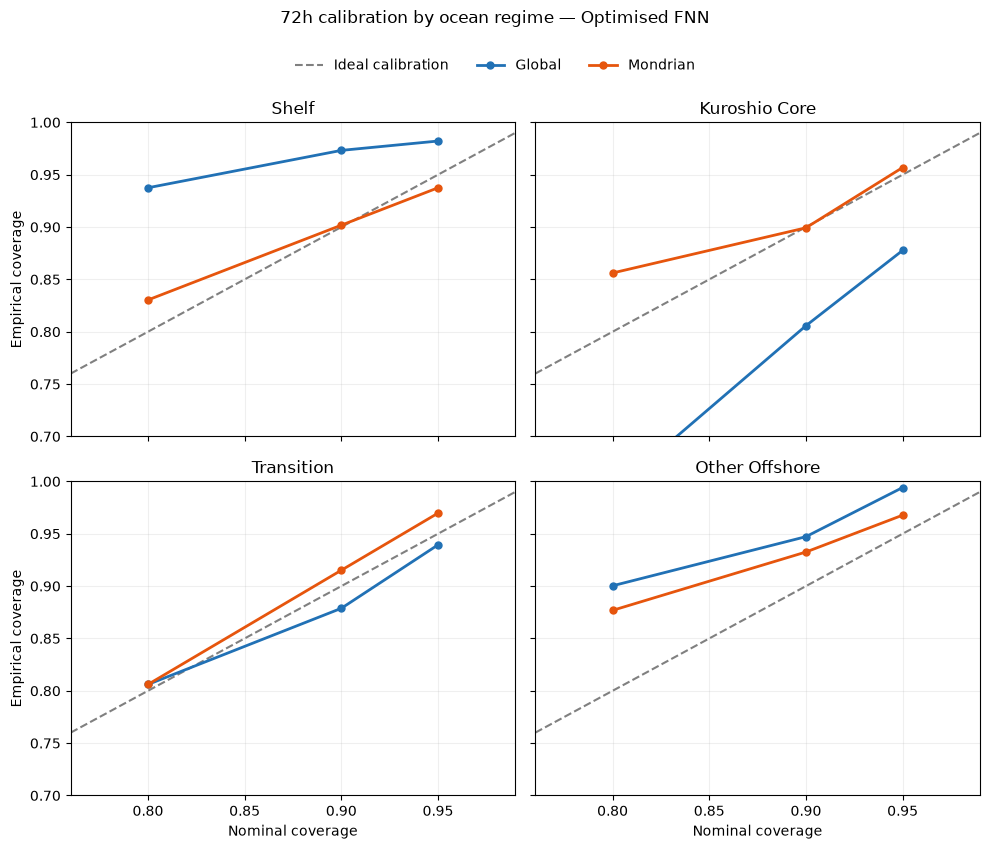

In [16]:
# ONE FIGURE, four panels, each with Global / Mondrian / ideal 45-degree line.
fig,axes=plt.subplots(2,2,figsize=(10,8),sharex=True,sharey=True)
colors={'Global':'#2171b5','Mondrian':'#e6550d'}
for ax,regime in zip(axes.flat,REGIMES):
    ax.plot([.75,1.0],[.75,1.0],'--',color='gray',label='Ideal calibration',lw=1.5)
    for method in ['Global','Mondrian']:
        d=results[(results.regime==regime)&(results.method==method)].sort_values('nominal_coverage')
        ax.plot(d.nominal_coverage,d.empirical_coverage,'o-',color=colors[method],label=method,lw=2,ms=5)
    ax.set_title(regime)
    ax.set_xlim(.76,.99);ax.set_ylim(.70,1.0)
    ax.grid(alpha=.2)
for ax in axes[-1,:]:ax.set_xlabel('Nominal coverage')
for ax in axes[:,0]:ax.set_ylabel('Empirical coverage')
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',ncol=3,bbox_to_anchor=(.5,1.01),frameon=False)
fig.suptitle('72h calibration by ocean regime — Optimised FNN',y=1.055)
fig.tight_layout()
fig.savefig(ROOT/'optimised_fnn_regime_calibration_4panel.png',dpi=220,bbox_inches='tight')
plt.show()


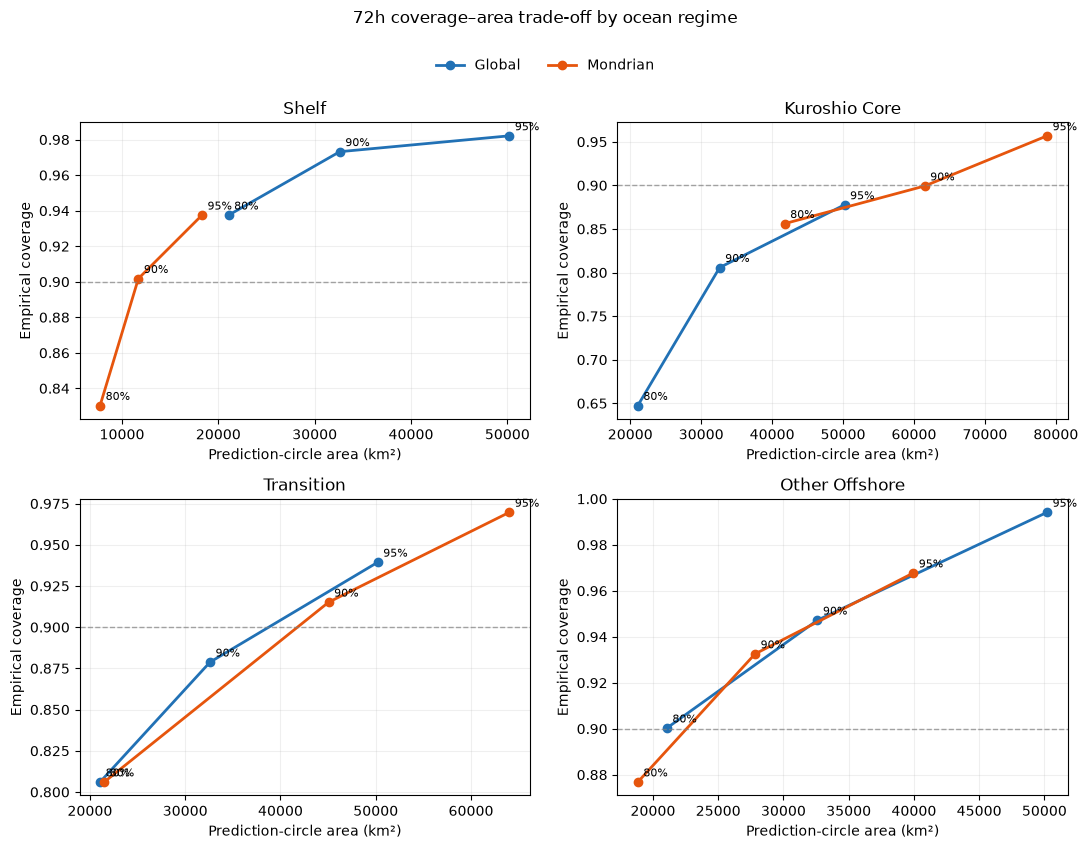

Saved CSV + two figures to: /Users/qiuyurui/Desktop/Data3001/RQ3/optimised_fnn/output


In [17]:
# ONE FIGURE, four panels, to compare achieved coverage versus prediction-circle area.
fig,axes=plt.subplots(2,2,figsize=(11,8))
for ax,regime in zip(axes.flat,REGIMES):
    for method in ['Global','Mondrian']:
        d=results[(results.regime==regime)&(results.method==method)].sort_values('nominal_coverage')
        ax.plot(d.area_km2,d.empirical_coverage,'o-',color=colors[method],label=method,lw=2)
        for _,r in d.iterrows():ax.annotate(f'{r.nominal_coverage:.0%}',(r.area_km2,r.empirical_coverage),xytext=(4,4),textcoords='offset points',fontsize=8)
    ax.axhline(.90,color='gray',ls='--',lw=1,alpha=.7)
    ax.set_title(regime)
    ax.set_xlabel('Prediction-circle area (km²)')
    ax.set_ylabel('Empirical coverage')
    ax.grid(alpha=.2)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',ncol=2,bbox_to_anchor=(.5,1.01),frameon=False)
fig.suptitle('72h coverage–area trade-off by ocean regime',y=1.055)
fig.tight_layout()
fig.savefig(ROOT/'optimised_fnn_regime_coverage_area_4panel.png',dpi=220,bbox_inches='tight')
plt.show()
print('Saved CSV + two figures to:',ROOT)
